# 0 Data upload

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/hidden_test.csv")

# 1 Data overview

## 1.1 Overview data shape

In [56]:
print("Train dataset shape", train.shape)
print("Test dataset shape", test.shape)


Train dataset shape (90000, 54)
Test dataset shape (10000, 53)


Notes: None

## 1.2 Overview a few first rows.

In [57]:
train.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,target
0,236,488,16,221,382,97,-4.472136,0.107472,0,132,281,336,99,3.880098,1.797502,3.252475,12.131981,3.091361,5.630319,4.466373,2.511203,5.982724,4.541159,12.740476,12.634929,4.050294,11.827245,3.568321,13.420537,8.251807,2.287900,14.834430,0.082253,2.975561,5.223753,1.212287,7.302797,7.083149,3.610350,7.767512,7.829657,8.395356,1.583711,10.125020,13.340874,0.870542,1.962937,7.466666,11.547794,8.822916,9.046424,7.895535,11.010677,20.107472
1,386,206,357,232,1,198,7.810250,0.763713,1,143,109,123,130,12.099770,10.670550,14.137111,0.217037,1.426881,0.916617,8.168254,0.432319,5.872218,10.401401,12.843301,7.529992,12.525335,8.655344,8.499587,5.602552,4.187738,13.205982,5.432667,12.379275,11.938420,6.057282,2.581280,11.785456,4.445564,11.141346,0.839731,1.481908,8.920653,4.450379,10.584802,12.484882,7.168680,2.885415,12.413973,10.260494,10.091351,9.270888,3.173994,13.921871,61.763713
2,429,49,481,111,111,146,8.602325,0.651162,1,430,488,138,80,2.947479,12.671352,13.279918,13.163338,9.051826,11.605822,11.094161,10.461813,9.827713,2.206019,9.914789,4.448482,8.864810,10.837476,14.167872,13.456857,14.855511,7.596095,4.928033,2.439930,6.791165,8.709536,1.363087,4.980975,2.182372,14.673614,8.083289,6.601472,6.789200,12.982035,10.273114,14.030257,0.394970,8.160625,12.592059,8.937577,2.265191,11.255721,12.794841,12.080951,74.651162
3,414,350,481,370,208,158,8.306624,0.424645,1,340,111,38,177,5.368252,6.765946,0.544415,7.175573,14.515096,1.901743,9.231263,9.600810,10.058844,5.680021,8.238473,0.272760,11.892743,4.030567,14.946749,7.121632,6.507572,12.462688,12.222522,0.318528,5.350321,3.143358,10.291804,13.105170,10.159100,3.671488,11.087198,1.289054,0.249375,2.967133,6.885179,2.789577,6.416708,10.549814,11.456437,6.468099,2.519049,0.258284,9.317696,5.383098,69.424645
4,318,359,20,218,317,301,8.124038,0.767304,1,212,141,417,343,14.592218,6.483629,9.159313,5.083046,8.772015,7.687242,11.106926,13.926358,0.914295,1.418124,4.504223,6.158475,1.790923,7.049614,14.409808,11.615837,5.675790,9.136146,10.640432,14.051122,2.240417,3.271828,5.061455,3.679880,2.948615,6.419577,14.873100,14.806887,9.992545,3.701959,11.162686,1.886560,1.919999,2.268203,0.149421,4.105907,10.416291,6.816217,8.586960,4.512419,66.767304


Notes:

8 looks boolean.\
6, 7, 13 and beyond look like floats.\
No categorical features spotted yet — need to check unique values.\
0–5, 9–12 are more likely int than categorical (large value ranges).\

## 1.3 Overview data types, and Non-Null 

In [58]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 54 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       90000 non-null  int64  
 1   1       90000 non-null  int64  
 2   2       90000 non-null  int64  
 3   3       90000 non-null  int64  
 4   4       90000 non-null  int64  
 5   5       90000 non-null  int64  
 6   6       90000 non-null  float64
 7   7       90000 non-null  float64
 8   8       90000 non-null  int64  
 9   9       90000 non-null  int64  
 10  10      90000 non-null  int64  
 11  11      90000 non-null  int64  
 12  12      90000 non-null  int64  
 13  13      90000 non-null  float64
 14  14      90000 non-null  float64
 15  15      90000 non-null  float64
 16  16      90000 non-null  float64
 17  17      90000 non-null  float64
 18  18      90000 non-null  float64
 19  19      90000 non-null  float64
 20  20      90000 non-null  float64
 21  21      90000 non-null  float64
 22  22      9

## 1.4 Overview of general statistical information

In [59]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
0,90000.0,249.423944,144.336393,0.000000,125.000000,250.000000,374.000000,499.000000
1,90000.0,250.236267,144.022200,0.000000,126.000000,251.000000,375.000000,499.000000
2,90000.0,248.637289,144.107577,0.000000,124.000000,248.000000,374.000000,499.000000
3,90000.0,249.736600,144.284945,0.000000,125.000000,250.000000,375.000000,499.000000
4,90000.0,249.436178,143.941581,0.000000,125.000000,250.000000,373.000000,499.000000
5,90000.0,249.656167,144.329168,0.000000,124.000000,250.000000,374.000000,499.000000
6,90000.0,-0.011402,7.038171,-9.949874,-7.071068,0.000000,7.000000,9.949874
7,90000.0,0.498548,0.288682,0.000014,0.248932,0.497136,0.747513,0.999987
8,90000.0,0.499189,0.500002,0.000000,0.000000,0.000000,1.000000,1.000000
9,90000.0,249.842033,144.612718,0.000000,124.000000,250.000000,376.000000,499.000000


Note:
- Columns 0–5, 9–12: Min ~0, Max ~499, Mean and Median ~250. Quartiles align strictly with quarters, resembling a uniform distribution.
- Column 6: Anomalous — median is 0, contains both positive and negative values, yet the mean is also close to 0.
- Column 7: Appears to be values from 0 to 1, with a median of 0.5 and quartiles at 0.25 and 0.75 (suggesting uniformity).
- Further columns unchecked. Looks very unusual; looks like all data has uniform distribution (like uniform noise).

## 1.5 Verify column consistency between the train and test datasets.

In [60]:
set(train.columns) - set(test.columns)

{'target'}

In [61]:
set(test.columns) - set(train.columns)

set()

Note: The columns are consistent.

# 2 Inspect data quality and check for duplicated or missing values.

## 2.1 Check for missing values

In [62]:
missing = train.isna().mean().sort_values(ascending=False)
missing[missing > 0]

Series([], dtype: float64)

## 2.2 Check for duplicates 

In [63]:
train.duplicated().sum()

np.int64(0)

## 2.3 Check for hidden categorical features

In [64]:
nunique = train.nunique().sort_values()
nunique.head(15)

8         2
6       199
2       500
0       500
3       500
4       500
5       500
1       500
12      500
9       500
10      500
11      500
7     90000
13    90000
14    90000
dtype: int64

Note: Column 8 is binary; no other categorical variables were found.

# 3 Overview target

## 3.1 Overview of general statistical information

In [65]:
train["target"].describe()

count    90000.000000
mean        50.033981
std         28.897243
min          0.002634
25%         25.091903
50%         50.030705
75%         75.059454
max         99.999482
Name: target, dtype: float64

Note: Checked train["target"].describe() and it looks weird again:
- Min ~0, Max ~100 (almost).
- Mean and median are both 50.
- Quartiles are at 25 and 75.
- Once again, it looks like a uniform distribution.
- Need to visualize it on a plot.

## 3.2 Plot target variable distribution

<Axes: xlabel='target', ylabel='Count'>

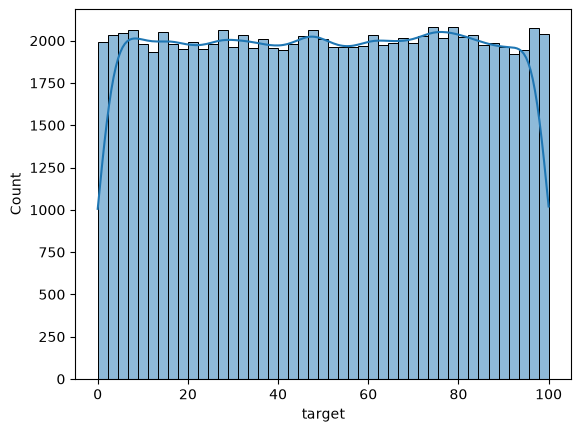

In [66]:
sns.histplot(train["target"], kde=True)

Note:\
Unexpected: the target actually has a uniform distribution.\
I suspect I was sent synthetic data or just pure noise.

## 3.3 Calculate baseline

In [67]:
baseline_rmse = train["target"].std()
baseline_rmse

np.float64(28.8972426922237)

Note: Baseline 28.8972426922237

# 4 Feature distribution

## 4.1 Plot features distribution

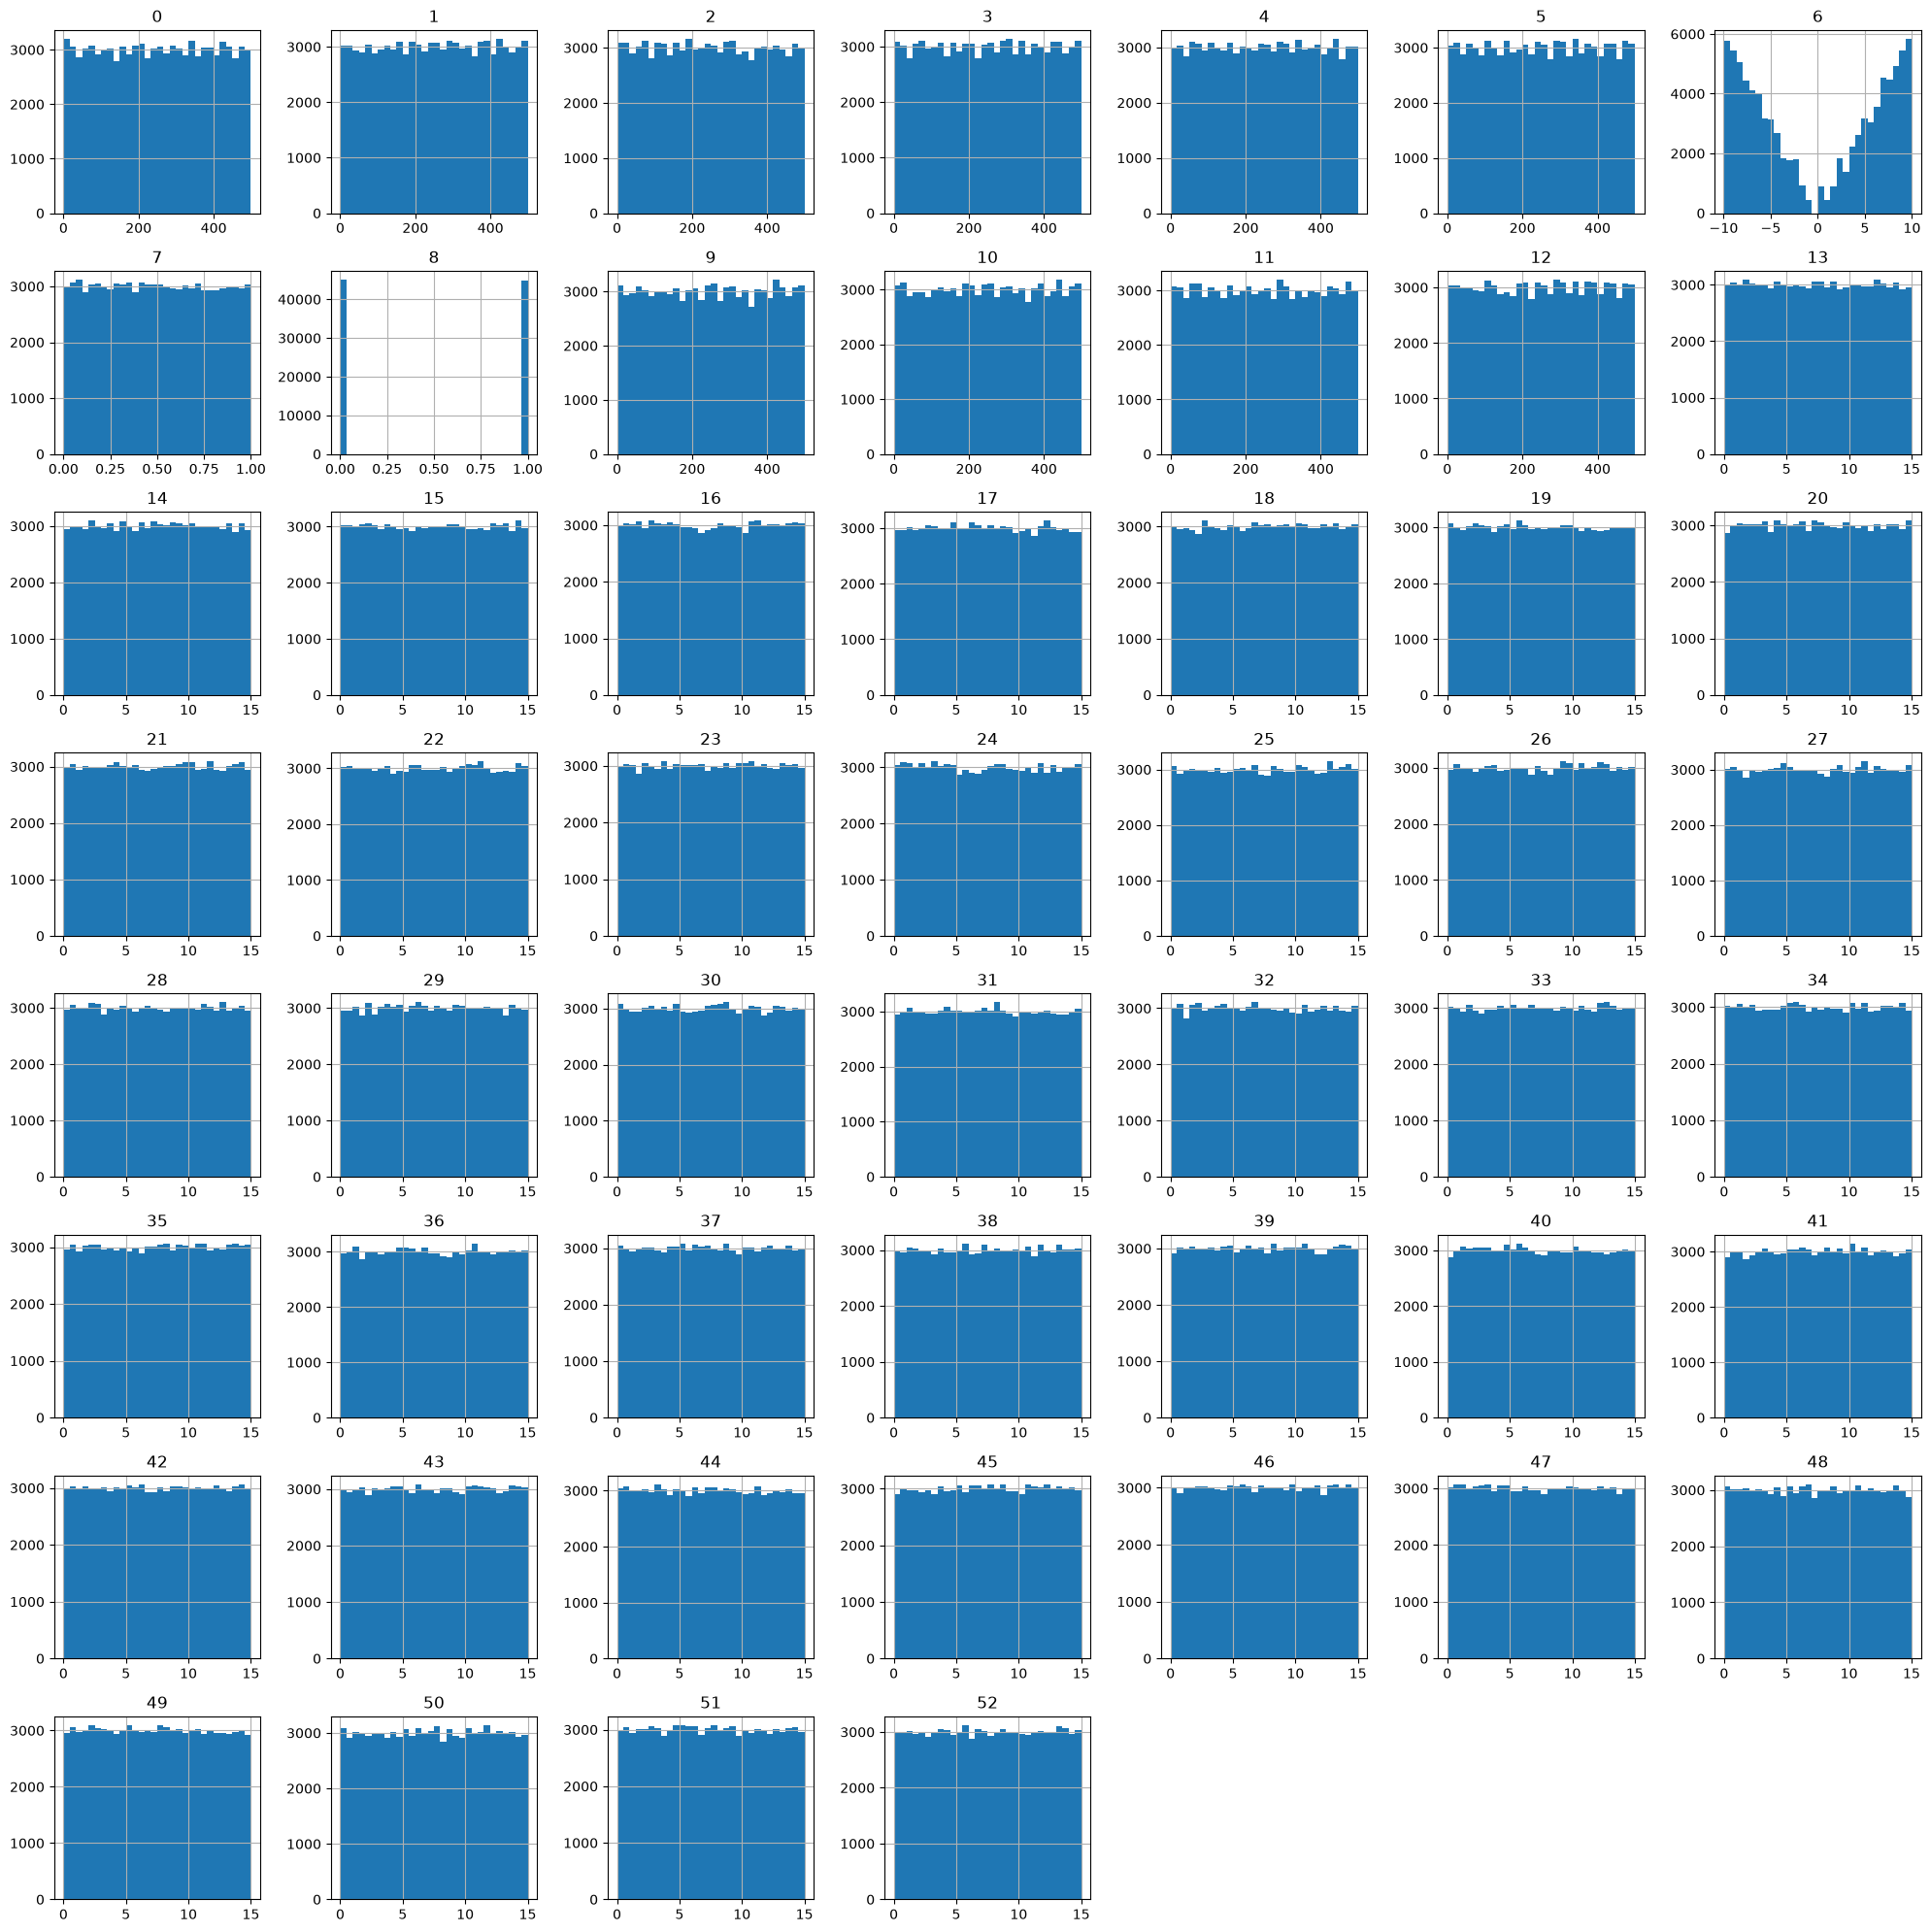

In [68]:
features = [c for c in train.columns if c != "target"]
train[features].hist(bins=30, figsize=(20, 20))
plt.tight_layout()

Note: All features except feature 6 actually have a uniform distribution.

## 4.2 Calculate correlation between features and target

In [69]:
corr = train.corr(numeric_only=True)["target"].drop("target").sort_values(key=abs, ascending=False)
corr.head(15)

7     0.012103
40   -0.007216
26    0.006370
39    0.006283
35   -0.006267
1    -0.005545
50   -0.005243
31    0.005077
29   -0.004785
51   -0.004507
25    0.004276
38   -0.003845
41   -0.003770
28    0.003451
10    0.003396
Name: target, dtype: float64

Note: Correlations for all features are around zero, except for feature 7, which is also close to zero.

## 4.3 Plot correlation between features

<Axes: >

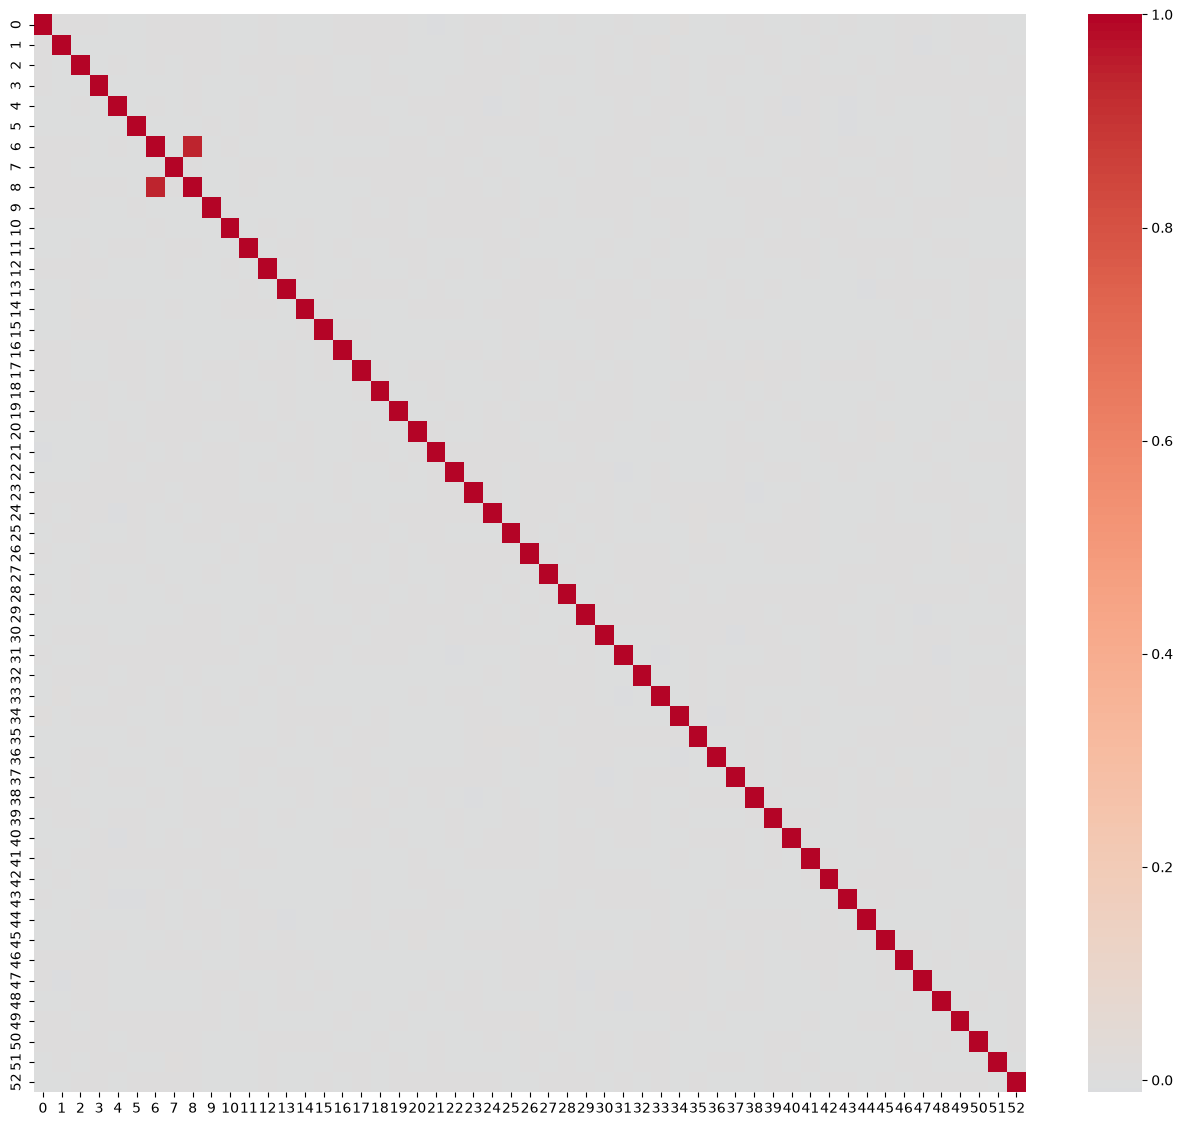

In [70]:
plt.figure(figsize=(16, 14))
sns.heatmap(train[features].corr(), cmap="coolwarm", center=0)

Note: Two features correlate strongly with each other (correlation ~ 1), while the rest show near-zero correlation.

## 4.4 Calculate correlation between features

In [71]:
c = train[features].corr().abs()
upper = c.where(np.triu(np.ones(c.shape), k=1).astype(bool))
upper.stack().sort_values(ascending=False).head(15)

6   8     0.940016
31  33    0.011606
26  49    0.010444
1   33    0.010357
4   43    0.009656
24  35    0.009283
25  35    0.009278
22  31    0.009036
34  47    0.009007
4   40    0.008978
5   43    0.008769
13  44    0.008637
37  46    0.008478
17  38    0.008472
20  45    0.008442
dtype: float64

Note: Columns 6 and 8 show a strong correlation.
- Column 6 is bimodal (two peaks with a dip in the middle).
- Column 8 is a boolean value.
Although neither correlates with the target, their mutual correlation suggests they might be related. Worth investigating.

In [72]:
pd.crosstab(train["6"] > 0, train["8"])

8,0,1
6,,
False,45073,468
True,0,44459


Note: I figured the boolean value acts as a classifier for whether column 6 is greater than zero.
Based on the results, that's exactly the case, though there might be a slight offset.

# 5 Outlier and aditional checks

In [73]:
Q1, Q3 = train[features].quantile(0.25), train[features].quantile(0.75)
IQR = Q3 - Q1
outlier_share = ((train[features] < Q1 - 1.5*IQR) | (train[features] > Q3 + 1.5*IQR)).mean()
outlier_share.sort_values(ascending=False).head(10)

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
5    0.0
6    0.0
7    0.0
8    0.0
9    0.0
dtype: float64

In [74]:
train["target"].skew()

np.float64(-0.004203005204950849)

# 5 Comparation between train dataset and test dataset. 

In [75]:
for col in features[:10]:
    print(col, "MEAN", train[col].mean(), test[col].mean(),"\t\tSTD", train[col].std(), test[col].std())

0 MEAN 249.42394444444443 248.3874 		STD 144.33639328527525 144.12452084565936
1 MEAN 250.23626666666667 250.1918 		STD 144.0221995395756 144.8503986068304
2 MEAN 248.6372888888889 248.0649 		STD 144.10757681723535 144.7922552062325
3 MEAN 249.7366 249.9922 		STD 144.2849451600316 144.01537133888934
4 MEAN 249.43617777777777 251.6422 		STD 143.94158099667052 144.7453242769866
5 MEAN 249.65616666666668 249.6786 		STD 144.32916822267 144.67768889986644
6 MEAN -0.0114016356738516 -0.07926782984313996 		STD 7.0381711924627215 7.032272882741517
7 MEAN 0.49854764874099256 0.5052146299467799 		STD 0.2886824035165942 0.2856784209917689
8 MEAN 0.4991888888888889 0.4922 		STD 0.5000021198956036 0.499964155130787
9 MEAN 249.84203333333335 245.8236 		STD 144.6127181292674 142.85205687723015


Note: The mean for feature 6 shows a relatively large difference (-0.011 vs -0.079 (diff ~0.06)), but this is likely negligible.

# 6 Apply Random Forest to identify potential predictive features and get early signals.

In [76]:
from sklearn.ensemble import RandomForestRegressor

In [77]:
# rf = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)
rf = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=5,random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(train[features], train["target"])
pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False).head(15)

6     9.999113e-01
7     8.869554e-05
31    3.143981e-11
18    2.995564e-11
9     2.708357e-11
37    2.612751e-11
43    2.547166e-11
40    2.529979e-11
49    2.506288e-11
1     2.469338e-11
17    2.430791e-11
36    2.419789e-11
46    2.397748e-11
47    2.388029e-11
13    2.382919e-11
dtype: float64

Note: Only feature 6 and slightly feature 7 showed any predictive power (Random Forest relied on them). Interestingly, feature 6 correlated with feature 8.\
I want to plot the target's dependence on feature 6 (is "target dependence on feature 6" a correct phrasing?). The rest data looks like noise.

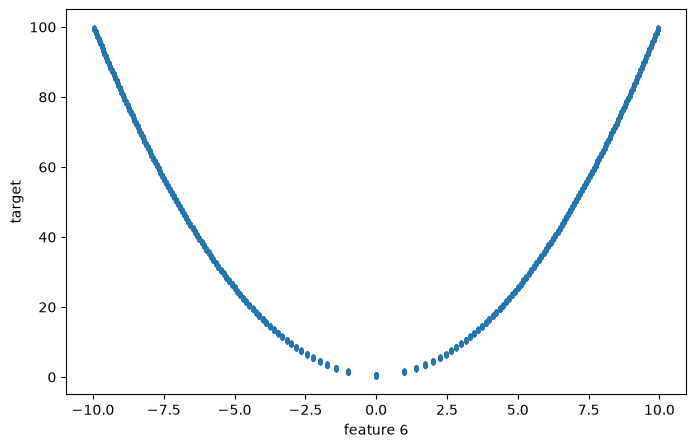

In [78]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(train["6"], train["target"], s=2, alpha=0.3)
plt.xlabel("feature 6")
plt.ylabel("target")
plt.show()

Note: Unexpected: there is a power-law-like relationship (or power relationship).\
It starts at (0, 0), and when feature 6 is 10, the target reaches 100 (around 5 it visually looks close to 25).\
Need to check this now.

In [79]:
feature = train["6"].to_numpy()
target = train["target"].to_numpy()

prediction = feature**2
mse = ((target - prediction)**2).mean()
rmse = np.sqrt(mse)

baseline_rmse = target.std()
print(rmse, baseline_rmse)

0.5760957925490628 28.897082151540573


Note: Calculated the new RMSE and got a better result than before — pretty happy with myself. Unclear why RMSE isn't 0 if I found the real function; could be noise or an offset. \
I want to check if there is a stable bias or something similar.

In [80]:
residual = target - prediction
print(residual.mean(), residual.std())

0.49854764874099233 0.2886807997210085


There is a stable bias/offset, though its mean doesn't match my RMSE (wondering if they can even be subtracted like that?). The standard deviation is non-zero, so it's not just a simple offset.
Re-evaluated the Random Forest results: another significant feature popped up — feature 7 (importance ~9.93e-05). It ranges from 0 to 1, so the mean is around 0.5. Need to check this.

In [81]:
print(train["7"].mean(), train["7"].std())

0.49854764874099256 0.2886824035165942


The numbers turned out to be similar: since the mean and std are very close, and feature 7 ranges from 0 to 1 (meaning the target is consistently higher than our prediction by about 0.5) while this variable's mean is around 0.5, \
I want to try adding it to the squared column 6 and see what happens.\
I had option to check with `print(np.corrcoef(target - prediction, train["7"])[0, 1])`

In [82]:
pred3 = train["6"]**2 + train["7"]
rmse3 = np.sqrt(((target - pred3)**2).mean())
print("RMSE:", rmse3)

RMSE: 9.687150056212742e-15


In [83]:
diff = target - pred3
print(residual.mean(), residual.std())

0.49854764874099233 0.2886807997210085


Decided that further digging isn't worth it, considering the residual to be a computation error/noise.\
Therefore, the final formula is:\
target = column["6"]**2 + column["7"]

# target = column["6"]**2 + column["7"]

# 7 Validate key features on the test dataset (both should have the same range and distribution)

In [84]:
cmp = pd.DataFrame({
    "tr_min": train[features].min(), "te_min": test[features].min(),
    "tr_max": train[features].max(), "te_max": test[features].max(),
    "tr_mean": train[features].mean(), "te_mean": test[features].mean(),
    "tr_std": train[features].std(), "te_std": test[features].std(),
})
cmp.loc[["6", "7"]]


,tr_min,te_min,tr_max,te_max,tr_mean,te_mean,tr_std,te_std
6,-9.949874,-9.949874,9.949874,9.949874,-0.011402,-0.079268,7.038171,7.032273
7,0.000014,0.000260,0.999987,0.999982,0.498548,0.505215,0.288682,0.285678


The issue with a significant mean discrepancy in column 6 was mentioned earlier. I looked into some materials and found specialized tools for comparing two distributions, specifically `ks_2samp`.\
Now we will check whether this discrepancy is actually an issue.

In [85]:
from scipy.stats import ks_2samp
for c in ["6", "7"]:
    print(c, ks_2samp(train[c], test[c]))

6 KstestResult(statistic=np.float64(0.007755555555555516), pvalue=np.float64(0.648227614934288), statistic_location=np.float64(-3.0), statistic_sign=np.int8(-1))


7 KstestResult(statistic=np.float64(0.014622222222222203), pvalue=np.float64(0.042202846605053135), statistic_location=np.float64(0.4458364464519064), statistic_sign=np.int8(1))


Feature 6: p-value is above the threshold at 0.6482, so data drift is considered unlikely.
Feature 7: p-value is below the threshold at 0.0422, but the statistic itself is very low at 0.0146. This means that if data drift exists, it is negligible (around 1.4%).

# target = column["6"]**2 + column["7"]

# Since the task is about General Machine Learning and I solved it using data science, I decided to run a few more ML tests.

# Machine Learning Approach

### Include Libraries

In [86]:
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from xgboost import XGBRegressor

SEED = 42
TARGET = "target"
TRAIN_PATH = "data/train.csv"
N_TRIALS = 30

### Read dataset

In [87]:
df = pd.read_csv(TRAIN_PATH)

### Check for Outliers

In [88]:
q1, q3 = df[TARGET].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = ((df[TARGET] < q1 - 1.5 * iqr) | (df[TARGET] > q3 + 1.5 * iqr)).sum()
print(f"Target Outliers (IQR Method): {outliers}")

Target Outliers (IQR Method): 0


### Train-Test Split

In [89]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print(f"train: {X_train.shape}, validation: {X_val.shape}")

train: (72000, 53), validation: (18000, 53)


### Building infrastructure for evaluation models

In [90]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

In [91]:
def rmse(y_true, y_pred) -> float:
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

In [92]:
def evaluate(models: dict, X_data: pd.DataFrame, y_data: pd.Series, cv_jobs: int = 1) -> pd.DataFrame:
    rows = []
    for name, model in models.items():
        scores = -cross_val_score(
            model, X_data, y_data, cv=cv,
            scoring="neg_root_mean_squared_error", n_jobs=-1,
        )
        rows.append({"model": name, "cv_rmse_mean": scores.mean(),
                     "cv_rmse_std": scores.std()})
    return pd.DataFrame(rows).sort_values("cv_rmse_mean").reset_index(drop=True)

### Init linear models 

In [93]:
linear_models = {
    "Mean (baseline)": DummyRegressor(strategy="mean"),
    "LinearRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0, random_state=SEED)),
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.1, random_state=SEED)),
    ]),
}


### Evaluating linear models on the dataset

In [94]:
linear_results_baseline = evaluate(linear_models, X_train, y_train)
print(linear_results_baseline.to_string(index=False))

           model  cv_rmse_mean  cv_rmse_std
           Lasso     28.870105     0.056356
 Mean (baseline)     28.870565     0.055769
           Ridge     28.881836     0.056982
LinearRegression     28.881837     0.056983


In [95]:
lasso = linear_models["Lasso"].fit(X_train, y_train)
coefs = pd.Series(lasso.named_steps["model"].coef_, index=X_train.columns)

print("Active lasso coefficients:")
print(coefs[coefs != 0].sort_values(key=abs, ascending=False))
print(f"\nZero-coefficient features: {(coefs == 0).sum()} из {len(coefs)}")

Active lasso coefficients:
7     0.209311
40   -0.199327
1    -0.163156
35   -0.137731
50   -0.135424
36    0.084926
39    0.079736
26    0.051077
28    0.039678
41   -0.038383
44    0.034013
38   -0.013884
10    0.009967
37    0.000720
dtype: float64

Zero-coefficient features: 39 из 53


### Linear models conclusion

* **Performance:** Linear models (LinearRegression, Ridge, Lasso) achieved a CV RMSE of ~28.87–28.88, matching the mean-prediction baseline (~28.87).
* **Model variance:** Performance differences between models (hundredths) are within fold-to-fold variation (std ~0.056) and are treated as noise.
* **Feature selection:** Lasso zeroed out 39 out of 53 features.

**Conclusion:** No linear relationship was found between features and the target, so linear models will not be pursued further.

**Next steps:** Moving on to non-linear approaches (trees, boosting, neural networks, and polynomial features). A significant drop in RMSE below the baseline will indicate the presence of non-linear patterns in the data.

### Evaluating non-linear models on the dataset

In [96]:
N_JOBS = 4

models = {
    "RandomForest": RandomForestRegressor(
        n_estimators=100, max_depth=12, min_samples_leaf=5,
        random_state=SEED, n_jobs=N_JOBS),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=100, max_depth=12, min_samples_leaf=5,
        random_state=SEED, n_jobs=N_JOBS),
    "LightGBM": LGBMRegressor(
        n_estimators=200, learning_rate=0.1, num_leaves=31,
        random_state=SEED, n_jobs=N_JOBS, verbose=-1),
    "XGBoost": XGBRegressor(
        n_estimators=200, learning_rate=0.1, max_depth=6,
        tree_method="hist", random_state=SEED, n_jobs=N_JOBS),
    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(hidden_layer_sizes=(32, 16), early_stopping=True, max_iter=200, random_state=SEED)),
    ]),
}

In [97]:
results_all = evaluate(models, X_train, y_train, N_JOBS)   # cv_jobs=1 по умолчанию
print(results_all.to_string(index=False))

       model  cv_rmse_mean  cv_rmse_std
    LightGBM      0.016933     0.000548
     XGBoost      0.017455     0.000430
  ExtraTrees      0.126874     0.008493
RandomForest      0.174083     0.009237
         MLP      0.583035     0.071529


### Non-linear models conclusion

* **Performance breakthrough:** Non-linear models significantly outperformed both the baseline (~28.87) and linear models.
* **Gradient boosting superiority:** LightGBM and XGBoost delivered the best results, dropping the error significantly below the baseline.
* **Tree-based & neural models:** Tree-based models (ExtraTrees, RandomForest) lagged behind boosting, while the MLP showed the poorest performance among non-linear models, likely due to underfitting under the current hyperparameters.

**Conclusion:** A strong non-linear relationship exists between the features and the target, which linear models failed to capture.

**Next steps:** Identify which features carry this signal and then tune hyperparameters for the top-performing models.

### Important feature selection

In [98]:
X_fit, X_hold, y_fit, y_hold = train_test_split(X_train, y_train, test_size=0.25, random_state=SEED)

In [99]:
lgbm_imp = LGBMRegressor(n_estimators=200, learning_rate=0.1, random_state=SEED, n_jobs=N_JOBS, verbose=-1)
lgbm_imp.fit(X_fit, y_fit)
None

In [100]:
perm = permutation_importance(
    lgbm_imp, X_hold, y_hold, n_repeats=10, random_state=SEED,
    scoring="neg_root_mean_squared_error", n_jobs=1,
)

In [101]:
importance = pd.DataFrame({
    "feature": X_train.columns,
    "mean": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("mean", ascending=False)

importance.head(10)

,feature,mean,std
6,6,40.802142,1.732251e-01
7,7,0.392596,8.101927e-04
34,34,0.000006,2.680986e-06
17,17,0.000006,1.807711e-06
21,21,0.000005,1.298503e-06
36,36,0.000004,2.404355e-06
30,30,0.000003,1.611235e-06
40,40,0.000003,7.608138e-07
22,22,0.000003,2.371253e-06
0,0,0.000002,1.723188e-06


* **Feature importance drop-off:** There is a significant gap in importance after the top 6–7 features. Features below this threshold have negligible impact and are treated as noise.
* **Selection:** Moving forward, the analysis will rely primarily on these top features (6 and 7) as the core predictors.

In [102]:
selected = importance["feature"].head(2).tolist()
print(selected)

['6', '7']


### Model evaluation on selected features

In [103]:
results_signal = evaluate(models, X_train[selected], y_train)
print(results_signal.to_string(index=False))

       model  cv_rmse_mean  cv_rmse_std
    LightGBM      0.015189     0.000547
     XGBoost      0.015792     0.000289
  ExtraTrees      0.131455     0.002501
RandomForest      0.174079     0.009238
         MLP      0.234262     0.022589


In [104]:
comparison = pd.DataFrame({
    "all_features": results_all.set_index("model")["cv_rmse_mean"],
    "signal_only": results_signal.set_index("model")["cv_rmse_mean"],
})
comparison["improvement_x"] = comparison["all_features"] / comparison["signal_only"]

comparison.sort_values("signal_only").round(4)

,all_features,signal_only,improvement_x
model,,,
LightGBM,0.0169,0.0152,1.1148
XGBoost,0.0175,0.0158,1.1053
ExtraTrees,0.1269,0.1315,0.9652
RandomForest,0.1741,0.1741,1.0000
MLP,0.5830,0.2343,2.4888


### Evaluating polynomial models

In [105]:
def poly_model(degree, regressor, scale=False):
    """Polynomial features of the given degree + a linear regressor."""
    steps = []
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("poly", PolynomialFeatures(degree=degree, include_bias=False)))
    steps.append(("model", regressor))
    return Pipeline(steps)


poly_models = {
    "Poly2 + Ridge": poly_model(2, Ridge(alpha=1.0, random_state=SEED), scale=True),
    "Poly3 + Ridge": poly_model(3, Ridge(alpha=1.0, random_state=SEED), scale=True),
    "Poly2 + LinearRegression": poly_model(2, LinearRegression()),
    "Poly3 + LinearRegression": poly_model(3, LinearRegression()),
}

results_poly = evaluate(poly_models, X_train[selected], y_train)

all_results = pd.concat([results_signal, results_poly])
print(all_results.sort_values("cv_rmse_mean").reset_index(drop=True))

                      model  cv_rmse_mean   cv_rmse_std
0  Poly2 + LinearRegression  1.623330e-14  6.089887e-15
1  Poly3 + LinearRegression  9.607543e-14  6.292245e-14
2             Poly2 + Ridge  1.481503e-03  4.684422e-06
3             Poly3 + Ridge  1.481763e-03  4.514691e-06
4                  LightGBM  1.518895e-02  5.473883e-04
5                   XGBoost  1.579175e-02  2.889143e-04
6                ExtraTrees  1.314546e-01  2.501416e-03
7              RandomForest  1.740793e-01  9.237516e-03
8                       MLP  2.342623e-01  2.258860e-02


Best-performing model: Poly2 combined with LinearRegression achieved the lowest RMSE, indicating it is a robust and appropriate model for this task.\
Extraction: Extracting the polynomial features.

In [106]:
final_pipeline = poly_models["Poly2 + LinearRegression"]
final_pipeline.fit(X_train[selected], y_train)

poly = final_pipeline.named_steps["poly"]
reg = final_pipeline.named_steps["model"]

raw_names = poly.get_feature_names_out()
names = ["x" + n.replace(" ", "*x") for n in raw_names]

coefs = pd.Series(reg.coef_, index=names)
intercept = reg.intercept_

print(coefs)
print("intercept:", intercept)

x6      -4.361648e-16
x7       1.000000e+00
x6^2     1.000000e+00
x6*x7    2.220446e-16
x7^2    -5.616167e-16
dtype: float64
intercept: -2.1316282072803006e-14


Extracted polynomial: The resulting formula is column[6]**2 + column[7], consistent with our findings from the EDA phase.

In [107]:
pred_val = final_pipeline.predict(X_val[selected])
print(f"Validation RMSE: {rmse(y_val, pred_val):.3e}")

Validation RMSE: 1.758e-14


In [111]:
import joblib
from sklearn.base import clone

final_model = clone(final_pipeline)
final_model.fit(X[selected], y)
joblib.dump({"model": final_model, "features": selected}, "models/eda_model.pkl")

['models/eda_model.pkl']

### Final model implementation

* **Polynomial performance:** Polynomial models achieved an RMSE close to zero, with minor discrepancies driven by computational precision limits.
* **Alternative approach:** LightGBM and XGBoost delivered the closest results among classical machine learning algorithms.

**Next steps:** Moving on to code implementation.

* **Deployment strategy:** The production code will include a formula-based prediction path if the analytical expression proves robust. As a fallback mechanism, it will use LightGBM—the most accurate classical algorithm for this task—in case the dependency varies or requires greater flexibility.